<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session09_ensemble_methods_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۹: روش‌های گروهی (Ensemble Learning)

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session09_ensemble_methods.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, StackingRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
housing = pd.read_csv(DATA_URL + "housing.csv")
housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_household"] = housing["population"] / housing["households"]
X = housing.drop(columns="median_house_value")
y = housing["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
numeric = X.select_dtypes("number").columns.tolist()
tree_prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), numeric),
                               ("cat", OrdinalEncoder(), ["ocean_proximity"])])

def rmse(model):
    return root_mean_squared_error(y_test, model.predict(X_test))

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

در Random Forest بخش ۳، `max_features` را ۱، ۳ و `None` قرار دهید (`None` یعنی همان Bagging). کدام بهتر است؟

</div>

In [2]:
for max_features in [1, 3, None]:
    forest = Pipeline([("prep", tree_prep), ("model", RandomForestRegressor(
        n_estimators=100, max_features=max_features, n_jobs=-1, random_state=42))]).fit(X_train, y_train)
    label = "None (bagging)" if max_features is None else max_features
    print(f"max_features={label!s:<15} test RMSE = {rmse(forest):,.0f}")

max_features=1               test RMSE = 55,601


max_features=3               test RMSE = 49,032


max_features=None (bagging)  test RMSE = 50,136


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- `max_features=1`: در هر گره فقط یک ویژگی تصادفی بررسی می‌شود؛ درخت‌ها بسیار متنوع ولی تک‌تک ضعیف‌اند.
- `max_features=None` (Bagging): همهٔ ویژگی‌ها بررسی می‌شوند؛ درخت‌ها قوی ولی شبیه هم‌اند.
- مقدار میانه معمولاً بهترین تعادل بین **قدرت** تک‌تک درخت‌ها و **تنوع** بینشان را دارد. پیش‌فرض scikit-learn برای رگرسیون `1.0` (همهٔ ویژگی‌ها) و برای طبقه‌بندی `"sqrt"` است؛ این ابرپارامتر ارزش تنظیم دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

شبیه‌سازی Gradient Boosting بخش ۵.۲ را با `learning_rate=0.3` و ۲۰ درخت تکرار کنید و منحنی نهایی را رسم کنید.

</div>

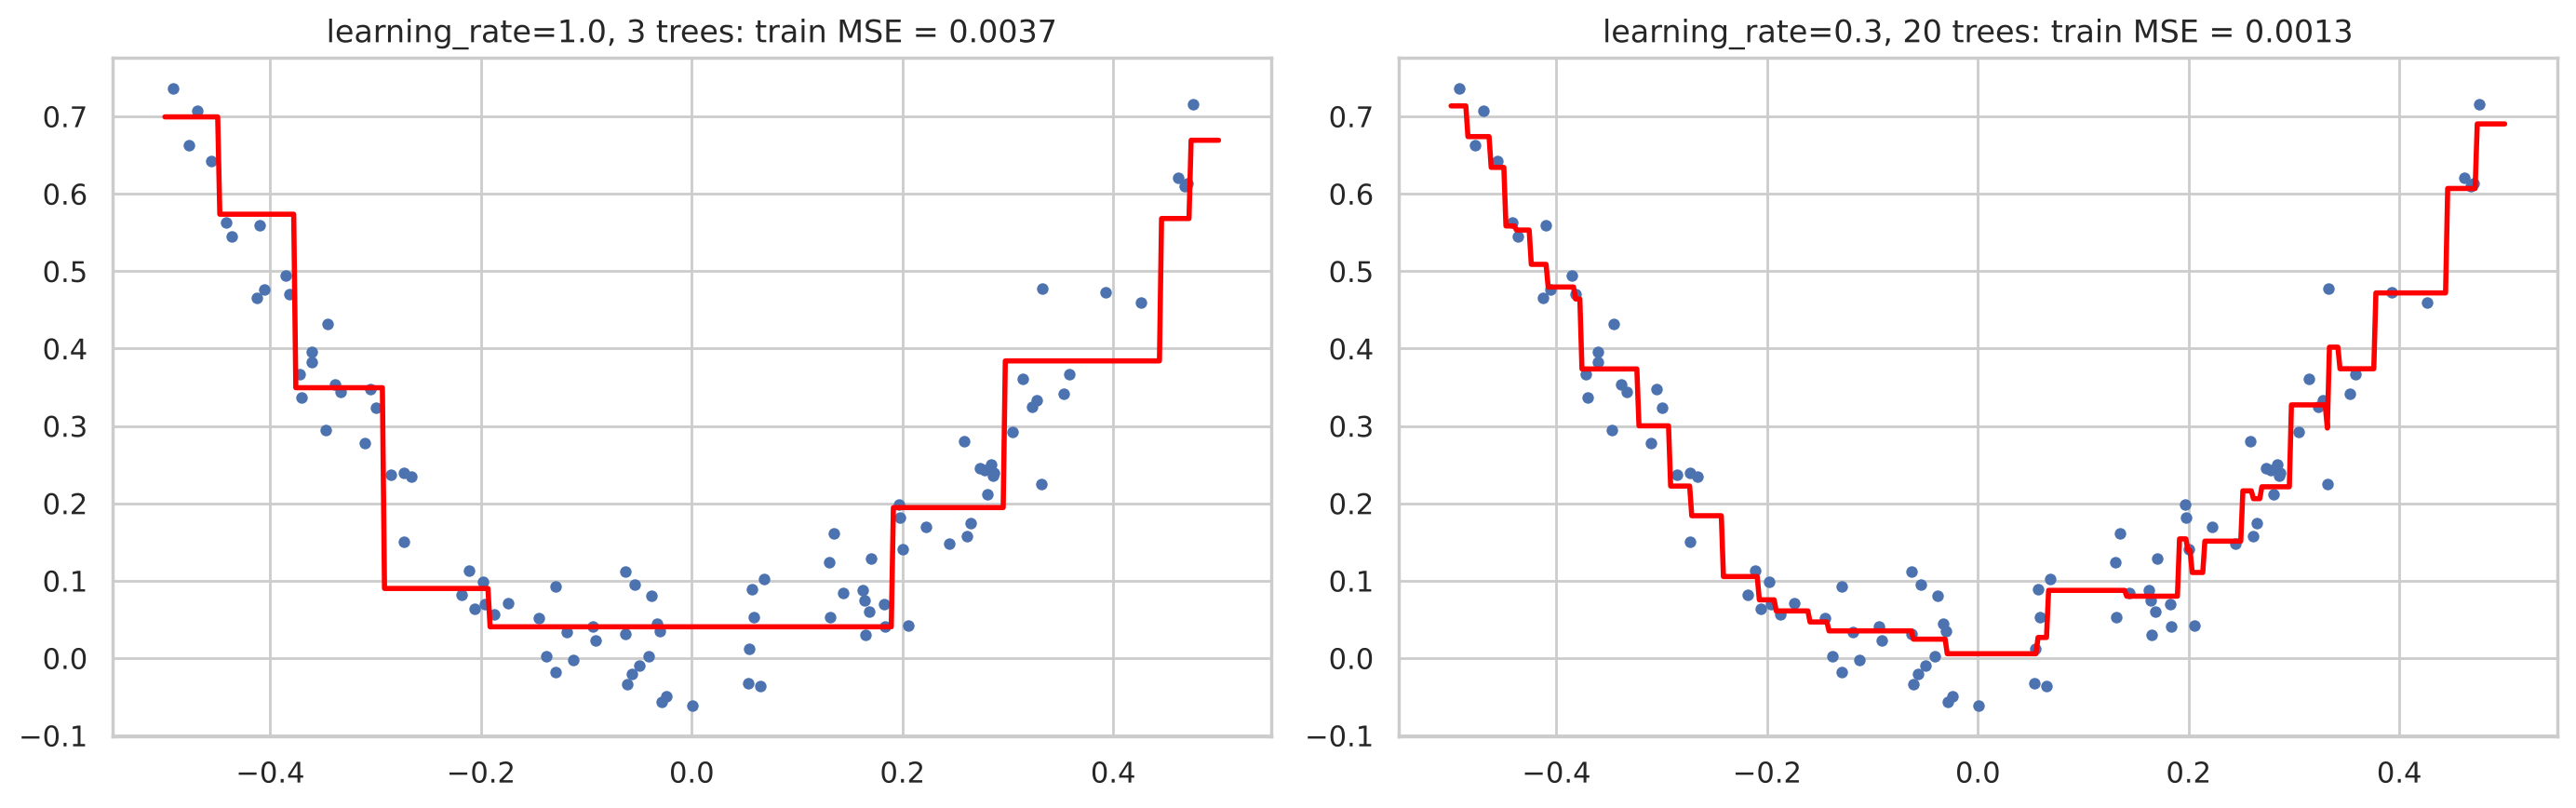

In [3]:
rng = np.random.default_rng(42)
X_s = rng.uniform(-0.5, 0.5, (100, 1))
y_s = 3 * X_s[:, 0] ** 2 + rng.normal(0, 0.05, 100)
x_plot = np.linspace(-0.5, 0.5, 500).reshape(-1, 1)

def boost(learning_rate, n_trees):
    pred, plot_pred = np.full(100, y_s.mean()), np.full(500, y_s.mean())
    for _ in range(n_trees):
        t = DecisionTreeRegressor(max_depth=2, random_state=42).fit(X_s, y_s - pred)
        pred += learning_rate * t.predict(X_s)
        plot_pred += learning_rate * t.predict(x_plot)
    return plot_pred, np.mean((y_s - pred) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (lr, n) in zip(axes, [(1.0, 3), (0.3, 20)]):
    curve, mse = boost(lr, n)
    ax.scatter(X_s, y_s, s=12)
    ax.plot(x_plot, curve, color="red", linewidth=2)
    ax.set_title(f"learning_rate={lr}, {n} trees: train MSE = {mse:.4f}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با نرخ یادگیری ۰٫۳، هر درخت فقط بخشی از خطای باقی‌مانده را اصلاح می‌کند؛ پس درخت‌های بیشتری لازم است، ولی منحنی نهایی **نرم‌تر** است و از پله‌های تیز سه درخت با نرخ ۱ کمتر رنج می‌برد. این همان ایدهٔ **shrinkage** است: قدم‌های کوچک‌تر و بیشتر، معمولاً تعمیم بهتری می‌دهند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

در `HistGradientBoostingRegressor`، به‌جای `OrdinalEncoder` از پارامتر `categorical_features="from_dtype"` استفاده کنید (ستون را به نوع `category` تبدیل کنید). نتیجه تغییر می‌کند؟

</div>

In [4]:
X_cat_train = X_train.astype({"ocean_proximity": "category"})
X_cat_test = X_test.astype({"ocean_proximity": "category"})

ordinal_model = Pipeline([("prep", tree_prep), ("model", HistGradientBoostingRegressor(random_state=42))])
ordinal_model.fit(X_train, y_train)
native_model = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=42)
native_model.fit(X_cat_train, y_train)

print(f"OrdinalEncoder + HistGB:           test RMSE = {rmse(ordinal_model):,.0f}")
print(f"Native categorical support (HistGB): test RMSE = "
      f"{root_mean_squared_error(y_test, native_model.predict(X_cat_test)):,.0f}")

OrdinalEncoder + HistGB:           test RMSE = 46,599
Native categorical support (HistGB): test RMSE = 46,191


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

نتیجه تقریباً یکسان است. پشتیبانی بومی از ویژگی‌های دسته‌ای به درخت اجازه می‌دهد در یک تقسیم، هر **زیرمجموعه‌ای** از دسته‌ها را جدا کند (نه فقط بر اساس ترتیب دلخواه کدها). وقتی ویژگی دسته‌ای فقط چند دسته دارد (اینجا ۵)، درخت با OrdinalEncoder هم با چند تقسیم به همان نتیجه می‌رسد. مزیت روش بومی برای ویژگی‌های دسته‌ای با دسته‌های زیاد بیشتر است. همچنین HistGradientBoosting مقادیر گمشده را خودش مدیریت می‌کند و به `SimpleImputer` نیازی ندارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

یک `StackingRegressor` با Random Forest، HistGradientBoosting و رگرسیون خطی بسازید و با بهترین مدل تکی مقایسه کنید.

</div>

In [5]:
linear_prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"]),
])
estimators = [
    ("forest", Pipeline([("prep", tree_prep), ("model", RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42))])),
    ("hgb", Pipeline([("prep", tree_prep), ("model", HistGradientBoostingRegressor(max_iter=500, random_state=42))])),
    ("linear", Pipeline([("prep", linear_prep), ("model", LinearRegression())])),
]
results = {}
for name, est in estimators:
    results[name] = rmse(est.fit(X_train, y_train))
stack = StackingRegressor(estimators=estimators, final_estimator=RidgeCV(), cv=5, n_jobs=-1).fit(X_train, y_train)
results["stacking"] = rmse(stack)
print(pd.Series(results, name="test RMSE").round(0))
print("\nWeights learned by the final model:", dict(zip([n for n, _ in estimators],
                                                        stack.final_estimator_.coef_.round(2))))

forest      50136.0
hgb         45758.0
linear      69127.0
stacking    45664.0
Name: test RMSE, dtype: float64

Weights learned by the final model: {'forest': np.float64(0.14), 'hgb': np.float64(0.89), 'linear': np.float64(-0.03)}


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

Stacking کمی از بهترین مدل تکی (HistGradientBoosting) بهتر است. وزن‌هایی که مدل نهایی یاد گرفته نشان می‌دهد بیشترین سهم را مدل‌های درختی دارند و رگرسیون خطی سهم کمی دارد. این بهبود کوچک، هزینهٔ آموزش چند برابر را دارد؛ برای همین Stacking بیشتر در مسابقات استفاده می‌شود تا در محصولات واقعی.

</div>